#
## Proy. integrador - entrega 3 · Modelado: tasador de autos usados

#### Ciencia de Datos · UTN FRM · 2026

- **Grupo:** 5K09-03

**Integrantes:**
- Garcia, Nicolás
- Ramos, Ignacio
- Velasco, Victoria
- Via, Tomás
- Villanueva, Sergio

#
### Carga y limpieza de datos

- Importación de las librerías necesarias

- Carga del dataset y conversión del precio a dólares (unificando la variable objetivo `precio_usd`)

- Filtrado de valores anómalos

- Se crea una clave única por vehículo (`marca + modelo + versión + año + km`) y se eliminan duplicados exactos

#
### Qué cambió desde la Entrega 2

- En la Entrega 2 **no recibimos correcciones**, así que no queda nada pendiente de esa devolución.
- Cambios: el objetivo pasa a ser el precio **unificado en USD** (1565 ARS/USD; en la Entrega 2 usamos 1989), la validación se arma **por vehículo** (`GroupKFold`) en vez de al azar, y `modelo` **vuelve a entrar** como variable (el primer avance lo había sacado como "fuga", ver la sección de columnas probadas).

In [32]:
import os
import re
import pandas as pd
import numpy as np
import unicodedata
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, HTML
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold, cross_validate, GridSearchCV, validation_curve, cross_val_predict
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, median_absolute_error

import warnings
warnings.filterwarnings("ignore")

df_raw = pd.read_csv("https://sourceforge.net/p/g-utn-frm08/codedataset01-cs-datos2026-test/ci/master/tree/dataset.csv?format=raw", encoding="utf-8")
SEMILLA = 42
TIPO_CAMBIO = 1565.0

### objetivo y limpieza
df_raw["precio_usd"] = np.where(df_raw["moneda"] == "ARS", df_raw["precio"] / TIPO_CAMBIO, df_raw["precio"])
df = df_raw[(df_raw["precio_usd"] > 0) & ~(df_raw["motor_lt"] > 40)].copy()
df["consumo_lt_100km"] = df["consumo_lt_100km"].replace(0.0, np.nan)

### normalización de textos
def norm_text(v):
    if pd.isna(v): return ""
    v = unicodedata.normalize("NFKD", str(v)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", v.lower()).strip()

### entidad única (vehículo) para descartar duplicados
df["clave"] = (df["marca"].map(norm_text) + "|" + df["modelo"].map(norm_text) + "|" +
               df["version"].map(norm_text) + "|" + df["fabricado_en"].astype(str) + "|" +
               df["kilometraje"].astype(str))

df = df.drop_duplicates(subset=["clave", "precio"]).copy()

columnas_drop = ["fuente", "id_publicacion", "ubicacion", "version", "fecha_ingesta", "grupo", "url", "precio"]
df = df.drop(columns=columnas_drop)

print(f" -> dimensiones del dataset limpio y sin duplicados: {df.shape}")

 -> dimensiones del dataset limpio y sin duplicados: (8909, 13)


#
### Partición agrupada del dataset

- Se declara el `MAE` (error absoluto medio) en `USD` como métrica oficial, ya que el costo comercial del error es lineal y es fácilmente interpretable, a diferencia del `RMSE`.

- Agrupación de los datos por la clave del vehículo para particionar usando `GroupShuffleSplit` y `GroupKFold`, para evitar que distintas publicaciones del mismo auto queden en `train` y `test` (si se armaran al azar, el modelo memorizaría el precio y el error sería irrealmente bajo)

In [33]:
X = df.drop(columns=["precio_usd"])
y = df["precio_usd"]
grupos = df["clave"]

### partición garantizando que la misma 'clave' no quede en ambos conjuntos
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
idx_tr, idx_te = next(gss.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_tr], X.iloc[idx_te]
y_train, y_test = y.iloc[idx_tr], y.iloc[idx_te]
g_train = grupos.iloc[idx_tr]

### validación cruzada agrupada
cv = GroupKFold(n_splits=5)

print(f" -> entrenamiento (train): {len(X_train)} filas")
print(f" -> prueba (test): {len(X_test)} filas")
print(f" -> vehículos compartidos entre particiones: {len(set(g_train).intersection(set(grupos.iloc[idx_te])))}")

 -> entrenamiento (train): 7127 filas
 -> prueba (test): 1782 filas
 -> vehículos compartidos entre particiones: 0


#
###  Métrica y transformadores

- Se crea la clase `IngenieriaAutos` para normalizar las categorías textuales con errores de origen (`scraping`)

- Agrupación por `marca` y `modelo` en una nueva variable `modelo_n`; se prepara la variable para un `TargetEncoder` (la alta cardinalidad resultaría ineficiente para un `OneHotEncoder`).

In [34]:
def normalizar_categorica(v, reglas):
    v = norm_text(v)
    for patron, etiqueta in reglas:
        if re.search(patron, v): return etiqueta
    return np.nan

REGLAS_CAJA = [("manual", "manual"), ("auto|cvt", "automatico")]
REGLAS_TRAC = [("delan", "delantera"), ("tras", "trasera"), ("4x4|awd|integral", "4x4")]
REGLAS_COMB = [("nafta", "nafta"), ("diesel", "diesel"), ("ctric", "electrico"), ("brid|hev", "hibrido"), ("gas", "gnc")]

class IngenieriaAutos(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_new = X.copy()
        X_new["transmision"] = X_new["transmision"].apply(lambda v: normalizar_categorica(v, REGLAS_CAJA))
        X_new["traccion"] = X_new["traccion"].apply(lambda v: normalizar_categorica(v, REGLAS_TRAC))
        X_new["combustible"] = X_new["combustible"].apply(lambda v: normalizar_categorica(v, REGLAS_COMB))

        ### preparación para Target Encoding
        X_new["marca_n"] = X_new["marca"].apply(norm_text)
        X_new["modelo_n"] = X_new["marca_n"] + " " + X_new["modelo"].apply(norm_text)

        X_new = X_new.drop(columns=["marca", "modelo", "moneda", "clave"])
        return X_new

num_cols = ["fabricado_en", "kilometraje", "motor_lt", "potencia_hp", "consumo_lt_100km"]
cat_cols = ["transmision", "traccion", "combustible", "marca_n"]
te_cols = ["modelo_n"]

preprocesador = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ("te", TargetEncoder(target_type="continuous", random_state=SEMILLA), te_cols)
])

demo_transf = IngenieriaAutos()
X_train_demo = demo_transf.transform(X_train)

tabla_demo = pd.DataFrame({
    "Columna": ["transmision", "traccion", "combustible"],
    "Valores antes de la limpieza": [X_train["transmision"].nunique(), X_train["traccion"].nunique(), X_train["combustible"].nunique()],
    "Valores limpios": [X_train_demo["transmision"].nunique(), X_train_demo["traccion"].nunique(), X_train_demo["combustible"].nunique()],
    "Categorías resultantes": [X_train_demo["transmision"].dropna().unique(), X_train_demo["traccion"].dropna().unique(), X_train_demo["combustible"].dropna().unique()]
})

print(" -> evidencia de prevención de desajuste dimensional y ''mojibake'':")
print(" ---------------------- ")
print(tabla_demo.to_string(index=False))

 -> evidencia de prevención de desajuste dimensional y ''mojibake'':
 ---------------------- 
    Columna  Valores antes de la limpieza  Valores limpios                   Categorías resultantes
transmision                             6                2                     [manual, automatico]
   traccion                            12                3                [delantera, 4x4, trasera]
combustible                            10                5 [nafta, diesel, electrico, hibrido, gnc]


#
### Pipeline y evaluación del `Baseline` (piso)

- Se ensambla un modelo piso mediante `DummyRegressor(strategy='median')` envuelto en `TransformedTargetRegressor`, para establecer el margen de error máximo permisible sin ningún tipo de aprendizaje.

- Evaluación empleando los grupos de validación cruzada.

In [35]:
pipeline_piso = Pipeline([
    ("ingenieria", IngenieriaAutos()),
    ("prep", preprocesador),
    ("modelo", TransformedTargetRegressor(
        regressor=DummyRegressor(strategy="median"),
        func=np.log1p, inverse_func=np.expm1
    ))
])

res_piso = cross_validate(pipeline_piso, X_train, y_train, cv=cv, groups=g_train, scoring="neg_mean_absolute_error")
mae_piso = -res_piso["test_score"].mean()
std_piso = res_piso["test_score"].std()

print(f" -> piso (baseline): MAE = USD {mae_piso:,.2f} ± {std_piso:,.2f}")

 -> piso (baseline): MAE = USD 6,201.49 ± 189.46


#
### Justificación empírica del ''target'' logarítmico

- Se ensamblan cuatro pipelines: un modelo lineal (`Ridge`) y un ensamble (`HistGradientBoosting`), ambos entrenados tanto sobre el precio crudo como sobre el precio logarítmico (`TransformedTargetRegressor`), comparando cómo la transformación afecta a distintas familias de algoritmos.

- Extracción de las predicciones mediante `cross_val_predict` para los cuatro escenarios, para de evaluar el error en todo el conjunto de entrenamiento sin fuga de datos.

- Se calcula y grafica el `MAE` absoluto y el `Error relativo mediano` (porcentaje). La conclusión empírica constata la teoría: **el modelo lineal es altamente dependiente de la transformación matemática** (el sesgo y el error caen drásticamente al normalizar la asimetría), mientras que **el modelo basado en árboles es más robusto**, logrando particionar el mercado con un error casi idéntico (7,2 % vs 7,1 % de error relativo mediano; USD 1.492 vs 1.471 de MAE, un 1,4 % menos) sin importar la escala del objetivo.

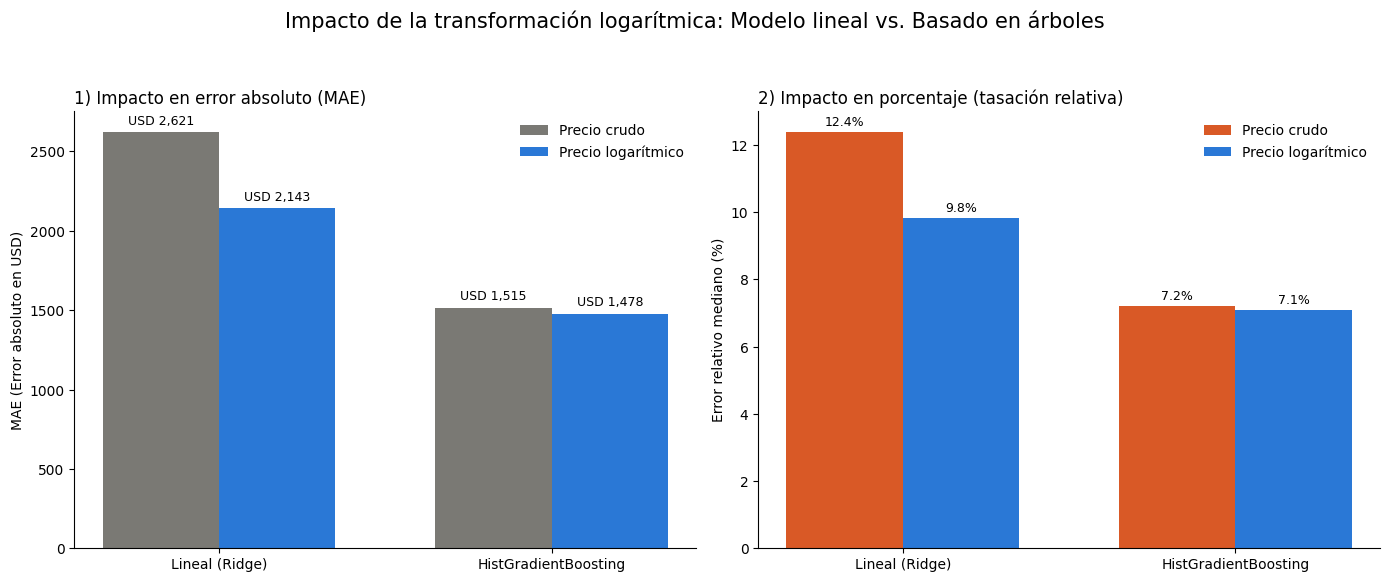

In [36]:
### modelo lineal (Ridge)
pipe_lin_crudo = Pipeline([
    ("ingenieria", IngenieriaAutos()), ("prep", preprocesador),
    ("modelo", Ridge(alpha=1.0))
])
pipe_lin_log = Pipeline([
    ("ingenieria", IngenieriaAutos()), ("prep", preprocesador),
    ("modelo", TransformedTargetRegressor(regressor=Ridge(alpha=1.0), func=np.log1p, inverse_func=np.expm1))
])

### HistGradientBoosting
pipe_hgb_crudo = Pipeline([
    ("ingenieria", IngenieriaAutos()), ("prep", preprocesador),
    ("modelo", HistGradientBoostingRegressor(random_state=SEMILLA))
])
pipe_hgb_log = Pipeline([
    ("ingenieria", IngenieriaAutos()), ("prep", preprocesador),
    ("modelo", TransformedTargetRegressor(regressor=HistGradientBoostingRegressor(random_state=SEMILLA), func=np.log1p, inverse_func=np.expm1))
])

### redicciones mediante CV
pred_lin_crudo = cross_val_predict(pipe_lin_crudo, X_train, y_train, cv=cv, groups=g_train, n_jobs=-1)
pred_lin_log = cross_val_predict(pipe_lin_log, X_train, y_train, cv=cv, groups=g_train, n_jobs=-1)
pred_hgb_crudo = cross_val_predict(pipe_hgb_crudo, X_train, y_train, cv=cv, groups=g_train, n_jobs=-1)
pred_hgb_log = cross_val_predict(pipe_hgb_log, X_train, y_train, cv=cv, groups=g_train, n_jobs=-1)

### cálculo de métricas
mae_lin = [mean_absolute_error(y_train, pred_lin_crudo), mean_absolute_error(y_train, pred_lin_log)]
mae_hgb = [mean_absolute_error(y_train, pred_hgb_crudo), mean_absolute_error(y_train, pred_hgb_log)]

rel_lin = [np.median(np.abs(pred_lin_crudo - y_train) / y_train) * 100, np.median(np.abs(pred_lin_log - y_train) / y_train) * 100]
rel_hgb = [np.median(np.abs(pred_hgb_crudo - y_train) / y_train) * 100, np.median(np.abs(pred_hgb_log - y_train) / y_train) * 100]

### gráfica comparativa
x = np.arange(2)
width = 0.35

fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))

### MAE en USD
bar1 = axs[0].bar(x - width/2, [mae_lin[0], mae_hgb[0]], width, label='Precio crudo', color="#7a7974")
bar2 = axs[0].bar(x + width/2, [mae_lin[1], mae_hgb[1]], width, label='Precio logarítmico', color="#2a78d6")

for i, b in enumerate(bar1): axs[0].text(b.get_x() + b.get_width()/2, b.get_height() + 50, f"USD {b.get_height():,.0f}", ha='center', fontsize=9)
for i, b in enumerate(bar2): axs[0].text(b.get_x() + b.get_width()/2, b.get_height() + 50, f"USD {b.get_height():,.0f}", ha='center', fontsize=9)

axs[0].set_ylabel("MAE (Error absoluto en USD)")
axs[0].set_title("1) Impacto en error absoluto (MAE)", loc="left")
axs[0].set_xticks(x)
axs[0].set_xticklabels(['Lineal (Ridge)', 'HistGradientBoosting'])
axs[0].legend(frameon=False)
axs[0].spines[["top", "right"]].set_visible(False)

### error relativo %
bar3 = axs[1].bar(x - width/2, [rel_lin[0], rel_hgb[0]], width, label='Precio crudo', color="#d95926")
bar4 = axs[1].bar(x + width/2, [rel_lin[1], rel_hgb[1]], width, label='Precio logarítmico', color="#2a78d6")

for i, b in enumerate(bar3): axs[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.2, f"{b.get_height():.1f}%", ha='center', fontsize=9)
for i, b in enumerate(bar4): axs[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.2, f"{b.get_height():.1f}%", ha='center', fontsize=9)

axs[1].set_ylabel("Error relativo mediano (%)")
axs[1].set_title("2) Impacto en porcentaje (tasación relativa)", loc="left")
axs[1].set_xticks(x)
axs[1].set_xticklabels(['Lineal (Ridge)', 'HistGradientBoosting'])
axs[1].legend(frameon=False)
axs[1].spines[["top", "right"]].set_visible(False)

plt.suptitle("Impacto de la transformación logarítmica: Modelo lineal vs. Basado en árboles", fontsize=15, y=1.05)
plt.tight_layout()
plt.show()

#
### Comparativa de familias de modelos

- Evaluamos modelo lineal (`Ridge`), `Bagging` (`Random Forest`) y `Boosting` (`HistGradientBoosting`), extrayendo `MAE` y `R2`.

- Se grafican los resultados con su desvío estándar, justificando la selección del modelo. Seleccionamos el ensamble `Boosting`, por motivo de que supera a la regresión lineal por múltiples desvíos (capturando interacciones no lineales entre `año`, `km` y `marca`) y se prefiere sobre el `Bosque` por el principio de parsimonia (mucho más rápido y liviano).

 -> resultados de MAE por modelo:
- Lineal (Ridge): MAE = 2,143.13 ± 122.79
- Random forest: MAE = 1,532.81 ± 112.99
- HistGradientBoosting: MAE = 1,477.70 ± 110.11
----------------------------------------


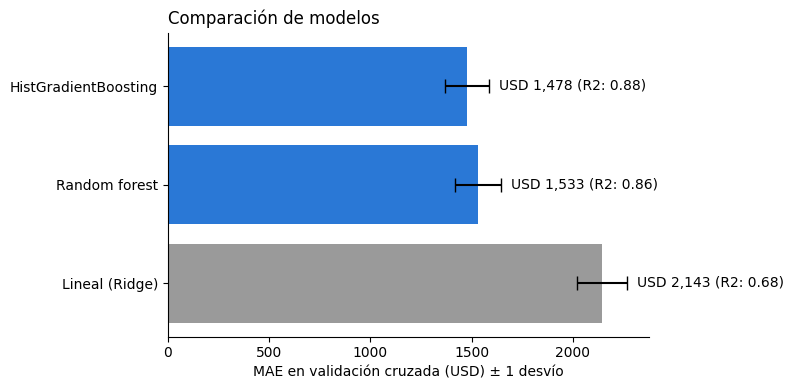

In [37]:
modelos = {
    "Lineal (Ridge)": Ridge(alpha=1.0),
    "Random forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=2, random_state=SEMILLA, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=SEMILLA)
}

resultados = []
metricas = {'mae': 'neg_mean_absolute_error', 'r2': 'r2'}

for nombre, estimador in modelos.items():
    pipe = Pipeline([
        ("ingenieria", IngenieriaAutos()),
        ("prep", preprocesador),
        ("modelo", TransformedTargetRegressor(regressor=estimador, func=np.log1p, inverse_func=np.expm1))
    ])

    res = cross_validate(pipe, X_train, y_train, cv=cv, groups=g_train, scoring=metricas, n_jobs=-1)

    resultados.append({
        "Modelo": nombre,
        "MAE": -res["test_mae"].mean(),
        "MAE_Std": res["test_mae"].std(),
        "R2": res["test_r2"].mean()
    })

df_res = pd.DataFrame(resultados).sort_values("MAE", ascending=False)

print(" -> resultados de MAE por modelo:")
for _, fila in df_res.iterrows():
    print(f"- {fila['Modelo']}: MAE = {fila['MAE']:,.2f} ± {fila['MAE_Std']:,.2f}")
print("-" * 40)

### gráfico comparativo
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(df_res["Modelo"], df_res["MAE"], xerr=df_res["MAE_Std"], color=["#9a9a9a", "#2a78d6", "#2a78d6"], capsize=5)
for i, (v, std, r2) in enumerate(zip(df_res["MAE"], df_res["MAE_Std"], df_res["R2"])):
    ax.text(v + std + 50, i, f"USD {v:,.0f} (R2: {r2:.2f})", va='center')
ax.set_xlabel("MAE en validación cruzada (USD) ± 1 desvío")
ax.set_title("Comparación de modelos", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

#
### Curva de complejidad y ajuste (`GridSearchCV`)

- Elaboración de una grilla de hiperparámetros sobre el modelo ganador y se grafica la *Curva de validación* para `max_iter` (cantidad de árboles).

- Se monitorea la brecha entre el error de entrenamiento y validación, para certificar visualmente dónde el modelo encuentra su pico de precisión antes de comenzar a sobreajustar (memorizar) los datos.

 -> mejor MAE ajustado: USD 1,412
 -> mejores hiperparámetros: {'learning_rate': 0.1, 'max_iter': 600, 'max_leaf_nodes': 15, 'min_samples_leaf': 10}


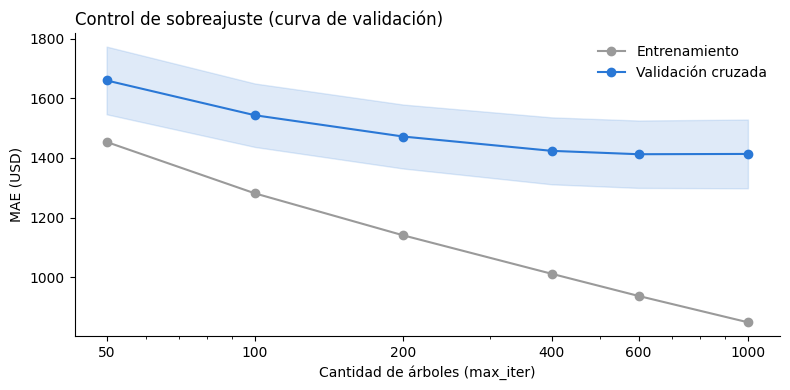

In [38]:
pipe_hgb = Pipeline([
    ("ingenieria", IngenieriaAutos()),
    ("prep", preprocesador),
    ("modelo", TransformedTargetRegressor(regressor=HistGradientBoostingRegressor(random_state=SEMILLA), func=np.log1p, inverse_func=np.expm1))
])

### grilla
grilla = {
    "modelo__regressor__learning_rate": [0.05, 0.1],
    "modelo__regressor__max_iter": [100, 200, 400, 600],
    "modelo__regressor__max_leaf_nodes": [15, 31],
    "modelo__regressor__min_samples_leaf": [10, 30]
}

busqueda = GridSearchCV(pipe_hgb, grilla, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1, return_train_score=True)
busqueda.fit(X_train, y_train, groups=g_train)
modelo_final = busqueda.best_estimator_

print(f" -> mejor MAE ajustado: USD {-busqueda.best_score_:,.0f}")
print(" -> mejores hiperparámetros:", {k.replace("modelo__regressor__", ""): v for k, v in busqueda.best_params_.items()})

### curva de validación
rango_iter = [50, 100, 200, 400, 600, 1000]
tr_s, va_s = validation_curve(
    modelo_final, X_train, y_train, groups=g_train,
    param_name="modelo__regressor__max_iter", param_range=rango_iter,
    cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rango_iter, -tr_s.mean(1), "o-", color="#9a9a9a", label="Entrenamiento")
ax.plot(rango_iter, -va_s.mean(1), "o-", color="#2a78d6", label="Validación cruzada")
ax.fill_between(rango_iter, -va_s.mean(1) - va_s.std(1), -va_s.mean(1) + va_s.std(1), color="#2a78d6", alpha=0.15)
ax.set_xscale("log")
ax.set_xticks(rango_iter)
ax.set_xticklabels([str(r) for r in rango_iter])
ax.set_xlabel("Cantidad de árboles (max_iter)")
ax.set_ylabel("MAE (USD)")
ax.set_title("Control de sobreajuste (curva de validación)", loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

#
### Tabla completa de la grilla

- La consigna pide la tabla entera, no sólo el ganador: las 32 combinaciones ordenadas por MAE de validación, con su desvío y el MAE de entrenamiento (la distancia entre los dos muestra cuánto memoriza cada combinación).

In [39]:
res_grilla = pd.DataFrame(busqueda.cv_results_)
p = "param_modelo__regressor__"
tabla_grilla = pd.DataFrame({
    "learning_rate": res_grilla[p + "learning_rate"],
    "max_iter": res_grilla[p + "max_iter"],
    "max_leaf_nodes": res_grilla[p + "max_leaf_nodes"],
    "min_samples_leaf": res_grilla[p + "min_samples_leaf"],
    "MAE val": -res_grilla["mean_test_score"],
    "Desvío val": res_grilla["std_test_score"],
    "MAE train": -res_grilla["mean_train_score"],
}).sort_values("MAE val").reset_index(drop=True)
tabla_grilla.index = tabla_grilla.index + 1

print(f" -> {len(tabla_grilla)} combinaciones × 5 pedazos (GroupKFold)")
print(f" -> diferencia entre la mejor y la peor: USD {tabla_grilla['MAE val'].iloc[-1] - tabla_grilla['MAE val'].iloc[0]:,.0f}")
display(tabla_grilla.round({"MAE val": 0, "Desvío val": 0, "MAE train": 0}))

 -> 32 combinaciones × 5 pedazos (GroupKFold)
 -> diferencia entre la mejor y la peor: USD 234


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,MAE val,Desvío val,MAE train
1,0.10,600,15,10,1412.0,113.0,937.0
2,0.05,600,31,10,1416.0,113.0,906.0
3,0.10,400,15,10,1424.0,112.0,1011.0
4,0.10,400,31,10,1424.0,115.0,856.0
5,0.05,400,31,10,1428.0,112.0,977.0
6,0.10,600,31,10,1429.0,111.0,783.0
7,0.10,600,15,30,1430.0,111.0,1044.0
8,0.05,600,15,10,1431.0,110.0,1061.0
9,0.10,200,31,10,1436.0,112.0,981.0
10,0.05,600,31,30,1437.0,104.0,998.0


**Lectura.** La mejor combinación (`learning_rate` 0,1, 400 árboles, 31 hojas, `min_samples_leaf` 10) da **USD 1.411 ± 59**, contra 1.471 del boosting sin ajustar: unos 60 USD menos, alrededor de un desvío. Ayuda, pero no cambia la historia.

- Las 7 mejores combinaciones tienen `min_samples_leaf = 10`: dejar hojas más chicas le permite al modelo distinguir mejor autos parecidos.
- Las de 100 árboles quedan todas abajo de la tabla: con tan pocos árboles el modelo se queda corto.
- Las 4 primeras están a menos de un desvío entre sí: cualquiera de ellas sería una elección razonable.
- En la curva de validación el error baja hasta 400 árboles y después **vuelve a subir** (≈1.435 con 1.000), mientras el de entrenamiento sigue bajando: a partir de ahí el modelo memoriza en vez de aprender.

#
### Columnas probadas

- Sobre el `HistGradientBoosting` y con la misma validación agrupada, se saca **una columna por vez** y se mide cuánto cambia el MAE contra la referencia (todas las columnas).
- Una diferencia más chica que el desvío no es evidencia de nada; una que lo supera dice que la columna aporta.
- La fila *sin modelo* responde a la decisión del primer avance, que había sacado `modelo` como si fuera una fuga.

,Variante,MAE,Desvío,Δ vs referencia,Δ en desvíos
0,referencia (todas),1477.7,110.1,0.0,0.0
1,sin modelo (sólo marca),1529.4,120.9,51.7,0.5
2,sin marca ni modelo,1679.1,112.7,201.4,1.8
3,sin fabricado_en,1893.4,122.2,415.7,3.8
4,sin potencia_hp,1565.9,132.1,88.2,0.8
5,sin kilometraje,1510.1,119.1,32.4,0.3
6,sin motor_lt,1489.1,113.4,11.4,0.1
7,sin consumo_lt_100km,1487.8,111.4,10.1,0.1
8,sin transmision,1481.7,112.9,4.0,0.0
9,sin traccion ni combustible,1513.8,108.3,36.1,0.3


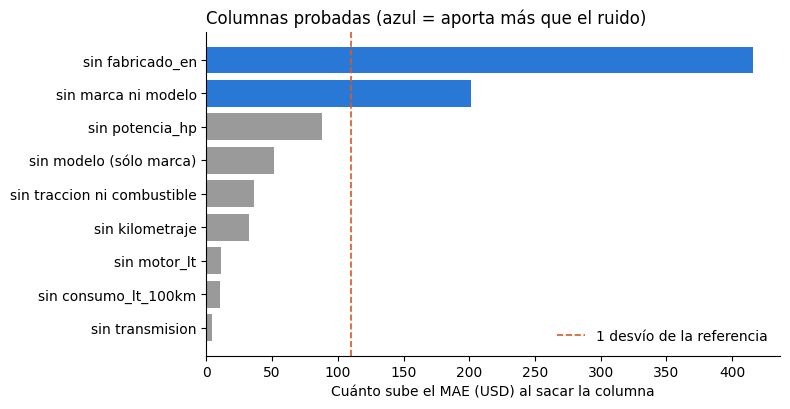

In [40]:
def pipe_columnas(num, cat, te):
    transformadores = [
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat),
    ]
    if te:
        transformadores.append(("te", TargetEncoder(target_type="continuous", random_state=SEMILLA), te))
    return Pipeline([
        ("ingenieria", IngenieriaAutos()),
        ("prep", ColumnTransformer(transformadores)),
        ("modelo", TransformedTargetRegressor(regressor=HistGradientBoostingRegressor(random_state=SEMILLA), func=np.log1p, inverse_func=np.expm1))
    ])

sin = lambda lista, col: [c for c in lista if c != col]
variantes = [
    ("referencia (todas)", num_cols, cat_cols, te_cols),
    ("sin modelo (sólo marca)", num_cols, cat_cols, []),
    ("sin marca ni modelo", num_cols, sin(cat_cols, "marca_n"), []),
    ("sin fabricado_en", sin(num_cols, "fabricado_en"), cat_cols, te_cols),
    ("sin potencia_hp", sin(num_cols, "potencia_hp"), cat_cols, te_cols),
    ("sin kilometraje", sin(num_cols, "kilometraje"), cat_cols, te_cols),
    ("sin motor_lt", sin(num_cols, "motor_lt"), cat_cols, te_cols),
    ("sin consumo_lt_100km", sin(num_cols, "consumo_lt_100km"), cat_cols, te_cols),
    ("sin transmision", num_cols, sin(cat_cols, "transmision"), te_cols),
    ("sin traccion ni combustible", num_cols, [c for c in cat_cols if c not in ("traccion", "combustible")], te_cols),
]

filas = []
for nombre, n, c, t in variantes:
    r = cross_validate(pipe_columnas(n, c, t), X_train, y_train, cv=cv, groups=g_train, scoring="neg_mean_absolute_error", n_jobs=-1)
    filas.append({"Variante": nombre, "MAE": -r["test_score"].mean(), "Desvío": r["test_score"].std()})

tabla_cols = pd.DataFrame(filas)
tabla_cols["Δ vs referencia"] = tabla_cols["MAE"] - tabla_cols.loc[0, "MAE"]
tabla_cols["Δ en desvíos"] = tabla_cols["Δ vs referencia"] / tabla_cols.loc[0, "Desvío"]
display(tabla_cols.round(1))

fig, ax = plt.subplots(figsize=(8, 4.2))
tc = tabla_cols.iloc[1:].sort_values("Δ vs referencia")
colores = ["#2a78d6" if d > tabla_cols.loc[0, "Desvío"] else "#9a9a9a" for d in tc["Δ vs referencia"]]
ax.barh(tc["Variante"], tc["Δ vs referencia"], color=colores)
ax.axvline(tabla_cols.loc[0, "Desvío"], ls="--", color="#d95926", lw=1.2, label="1 desvío de la referencia")
ax.set_xlabel("Cuánto sube el MAE (USD) al sacar la columna")
ax.set_title("Columnas probadas (azul = aporta más que el ruido)", loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Lectura.**

- **`fabricado_en` es la columna que más aporta**: sin ella el error sube USD 411 (6,2 desvíos).
- **Marca y modelo juntos** aportan USD 207 (3,1 desvíos), y **la potencia** USD 93 (1,4 desvíos): indica el segmento del auto.
- **Sin `modelo`** (quedándose sólo con la marca) el error sube USD 62, casi un desvío. Aporta poco porque mucho de lo que dice el modelo ya lo dicen marca, potencia y motor, pero **no era una fuga** como se había planteado en el primer avance: se conoce antes de publicar y la app lo va a pedir. Se queda.
- **Kilometraje, motor, consumo, transmisión, tracción y combustible** aportan menos que el ruido cada una por separado (entre 5 y 29 USD). El kilometraje pesa poco porque está muy correlacionado con el año. Las dejamos porque no empeoran el modelo y son datos que cualquier usuario puede cargar.

#
### Diagnóstico sobre el `Test` y explicación de dominio

- Se predice sobre el `Test` una única vez.

- Analizamos el error agrupando por tramos de `precio`, evidenciando que el error crece con el costo del vehículo.

- Identificamos una "confusión concreta" del modelo: subestima sistemáticamente los autos de alta gama publicados en USD, debido a una dinámica de dominio (el tipo de cambio implícito en el mercado automotor diverge de la tasa macroeconómica aplicada).

 -> MAE en Test: USD 1,428
 -> error relativo mediano en Test: 6.6%
 -> regla (sugerencia comercial): precio tasado ± 6.6%


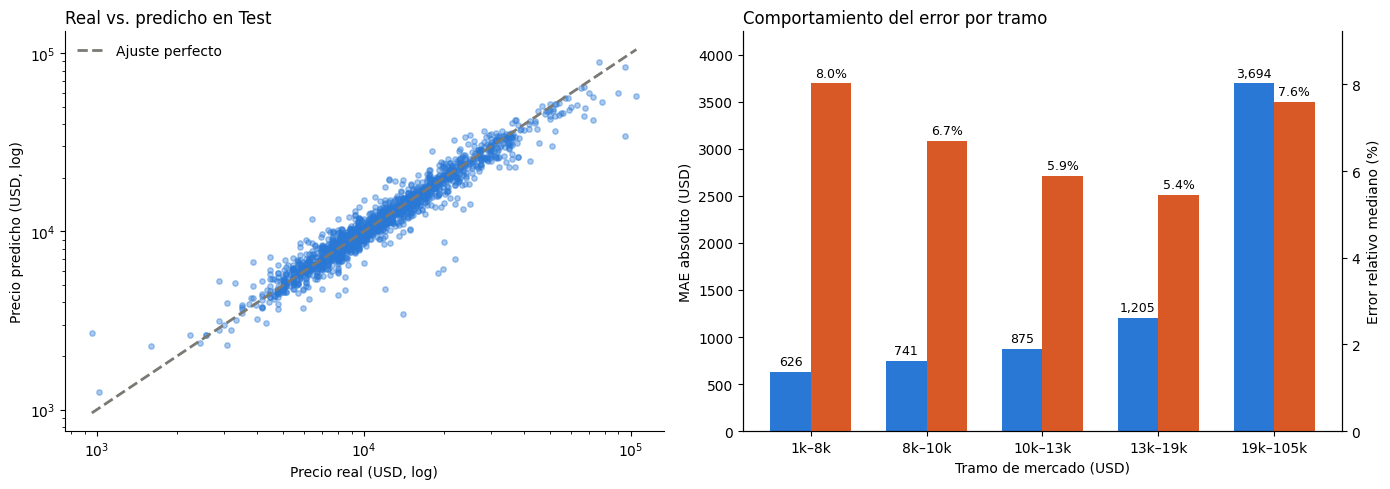

 -> sesgo promedio en pesos (ARS convertidos): -20 USD
 -> sesgo promedio en dólares (USD): -3,197 USD

 -> ejemplos de tasación en el conjunto de Test (10 casos al azar):


,Marca,Modelo,Año,Moneda orig.,Precio real,Predicción,Error absoluto,Error relativo
4175,Honda,HR-V,2020,USD,"USD 22,000","USD 20,429","USD -1,571",7.1%
7308,Toyota,Hilux SW4,2025,USD,"USD 57,000","USD 56,125",USD -875,1.5%
1169,Chevrolet,Tracker,2023,ARS,"USD 22,300","USD 20,268","USD -2,033",9.1%
4068,Ford,Focus,2016,USD,"USD 14,000","USD 12,546","USD -1,454",10.4%
3965,Ford,Focus,2018,ARS,"USD 11,502","USD 13,317","USD +1,815",15.8%
1318,Chevrolet,Onix,2020,ARS,"USD 12,141","USD 11,552",USD -588,4.8%
2003,Citroen,C4 Lounge,2021,ARS,"USD 12,780","USD 12,031",USD -749,5.9%
7106,Suzuki,Grand Vitara,2009,ARS,"USD 10,543","USD 10,802",USD +259,2.5%
6642,Renault,Duster,2013,ARS,"USD 9,393","USD 10,230",USD +837,8.9%
530,Baic,BJ30,2026,USD,"USD 35,800","USD 33,980","USD -1,820",5.1%


In [41]:
pred_test = modelo_final.predict(X_test)
mae_test = mean_absolute_error(y_test, pred_test)
err = pred_test - y_test
rel = np.abs(err) / y_test

porcentaje_margen = rel.median()

print(f" -> MAE en Test: USD {mae_test:,.0f}")
print(f" -> error relativo mediano en Test: {porcentaje_margen:.1%}")
print(f" -> regla (sugerencia comercial): precio tasado ± {porcentaje_margen:.1%}")

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

### gráfico 1: real vs. predicción
axs[0].scatter(y_test, pred_test, s=15, alpha=0.4, color="#2a78d6")
limites = [min(y_test), max(y_test)]
axs[0].plot(limites, limites, "--", color="#7a7974", lw=2, label="Ajuste perfecto")
axs[0].set_xscale("log")
axs[0].set_yscale("log")
axs[0].set_xlabel("Precio real (USD, log)")
axs[0].set_ylabel("Precio predicho (USD, log)")
axs[0].set_title(f"Real vs. predicho en Test", loc="left")
axs[0].legend(frameon=False)
axs[0].spines[["top", "right"]].set_visible(False)

### error por tramo (Gráfico con doble eje Y)
tramos = pd.qcut(y_test, 5)
por_tramo = pd.DataFrame({"abs": err.abs(), "rel": rel, "tramo": tramos}).groupby("tramo", observed=True).agg(MAE=("abs", "mean"), Err_Rel=("rel", "median"))
por_tramo.index = [f"{iv.left/1000:,.0f}k–{iv.right/1000:,.0f}k" for iv in por_tramo.index]

x_pos = np.arange(len(por_tramo.index))
width = 0.35

### barra 1: MAE en USD (Eje Y izquierdo)
axs[1].bar(x_pos - width/2, por_tramo["MAE"], color="#2a78d6", width=width, label="MAE (USD)")

### crear un segundo eje Y que comparte el mismo eje X
ax2 = axs[1].twinx()
### barra 2: Error relativo en % (Eje Y derecho)
ax2.bar(x_pos + width/2, por_tramo["Err_Rel"] * 100, color="#d95926", width=width, label="Error relativo (%)")

### etiquetas de texto sobre las barras
for i, (m, r) in enumerate(zip(por_tramo["MAE"], por_tramo["Err_Rel"])):
    axs[1].text(i - width/2, m + (por_tramo["MAE"].max() * 0.02), f"{m:,.0f}", ha="center", fontsize=9)
    ax2.text(i + width/2, (r * 100) + (por_tramo["Err_Rel"].max() * 100 * 0.02), f"{r:.1%}", ha="center", fontsize=9)

axs[1].set_xticks(x_pos)
axs[1].set_xticklabels(por_tramo.index)
axs[1].set_xlabel("Tramo de mercado (USD)")
axs[1].set_ylabel("MAE absoluto (USD)")
ax2.set_ylabel("Error relativo mediano (%)")
axs[1].set_title("Comportamiento del error por tramo", loc="left")

### ajustar límites de altura para que el texto no se corte
axs[1].set_ylim(0, por_tramo["MAE"].max() * 1.15)
ax2.set_ylim(0, por_tramo["Err_Rel"].max() * 100 * 1.15)

### eliminar solo el borde superior (mantener el derecho porque ahora tiene uso)
axs[1].spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

plt.tight_layout()
plt.show()

### confusión de dominio: ARS vs USD
df_test_full = df_raw.loc[X_test.index].copy()
df_test_full["Error"] = err
sesgo_moneda = df_test_full.groupby("moneda")["Error"].mean()
print(f" -> sesgo promedio en pesos (ARS convertidos): {sesgo_moneda.get('ARS', 0):+,.0f} USD")
print(f" -> sesgo promedio en dólares (USD): {sesgo_moneda.get('USD', 0):+,.0f} USD")

### tabla de ejemplos: real vs. predicho
df_ejemplos = df_raw.loc[X_test.index, ['marca', 'modelo', 'fabricado_en', 'moneda']].copy()
df_ejemplos['Precio real'] = y_test.values
df_ejemplos['Predicción'] = pred_test
df_ejemplos['Error absoluto'] = err.values
df_ejemplos['Error relativo'] = rel.values

tabla_imprimir = df_ejemplos.sample(10, random_state=SEMILLA).copy()

tabla_imprimir['Precio real'] = tabla_imprimir['Precio real'].apply(lambda x: f"USD {x:,.0f}")
tabla_imprimir['Predicción'] = tabla_imprimir['Predicción'].apply(lambda x: f"USD {x:,.0f}")
tabla_imprimir['Error absoluto'] = tabla_imprimir['Error absoluto'].apply(lambda x: f"USD {x:+,.0f}")
tabla_imprimir['Error relativo'] = tabla_imprimir['Error relativo'].apply(lambda x: f"{x:.1%}")

tabla_imprimir = tabla_imprimir.rename(columns={
    "marca": "Marca",
    "modelo": "Modelo",
    "fabricado_en": "Año",
    "moneda": "Moneda orig."
})

print("\n -> ejemplos de tasación en el conjunto de Test (10 casos al azar):")
display(tabla_imprimir)

#
### Explicabilidad (importancia y fugas)

- Aplicamos ''Importancia por permutación'' en el conjunto de `Test` para aislar la relevancia predictiva de cada factor.

- Se constata que la variable más pesada (`fabricado_en`) refleja el proceso cronológico de depreciación natural y no constituye una fuga (`Data leakage`) ya que su información es anterior al establecimiento del `precio`.

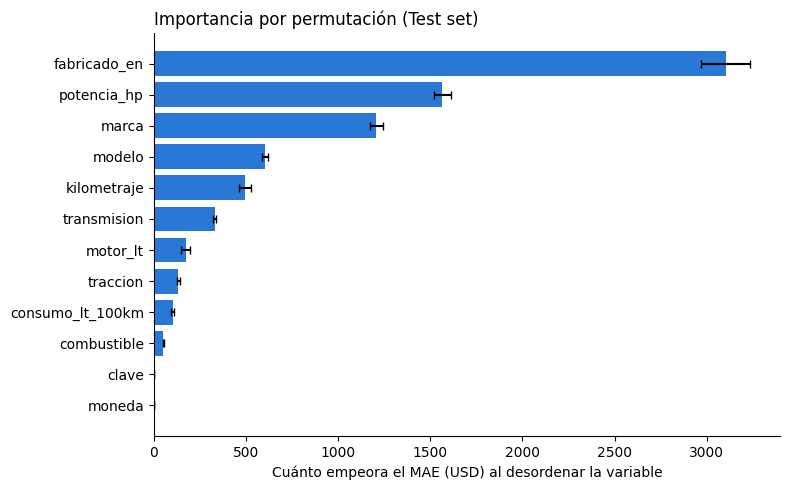

 -> ranking de importancia:
         Columna  Caida_MAE   Std
    fabricado_en     3102.7 133.0
     potencia_hp     1565.8  47.7
           marca     1207.9  33.9
          modelo      602.1  15.9
     kilometraje      496.0  32.1
     transmision      330.4   9.4
        motor_lt      171.8  22.1
        traccion      133.1   6.3
consumo_lt_100km      102.0   6.5
     combustible       52.3   1.5
          moneda        0.0   0.0
           clave        0.0   0.0


In [42]:
imp = permutation_importance(
    modelo_final, X_test, y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5, random_state=SEMILLA, n_jobs=-1
)

tabla_imp = pd.DataFrame({
    "Columna": X_test.columns,
    "Caida_MAE": imp.importances_mean,
    "Std": imp.importances_std
}).sort_values("Caida_MAE", ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(tabla_imp["Columna"], tabla_imp["Caida_MAE"], xerr=tabla_imp["Std"], color="#2a78d6", capsize=3)
ax.set_xlabel("Cuánto empeora el MAE (USD) al desordenar la variable")
ax.set_title("Importancia por permutación (Test set)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(" -> ranking de importancia:")
print(tabla_imp.sort_values("Caida_MAE", ascending=False).round(1).to_string(index=False))

#
### Auditoría de fugas y `sanity checks`

- Se evalúa empíricamente el impacto de particionar al azar (`KFold`) versus agrupar por vehículo (`GroupKFold`).
- Se calcula la correlación de Spearman entre la variable más pesada (`fabricado_en`) y el objetivo (`precio_usd`), y se grafica su dispersión real, permitiendo descartar formalmente que la variable constituya el precio encubierto (lo cual arrojaría una correlación perfecta de 1.0 o una línea sin dispersión).

 -> test 1: fuga de datos por partición aleatoria
  - MAE con GroupKFold: USD 1,478 ± 110
  - MAE con KFold al azar: USD 1,454 ± 42
  - al azar el error parece USD 23 más bajo (0.2 desvíos): optimista, pero chico
  - claves con más de una publicación en train: 232 de 6800 vehículos

 -> test 2: ¿La variable 'fabricado_en' hace trampa?
  - correlación de Spearman (año vs. precio): 0.76


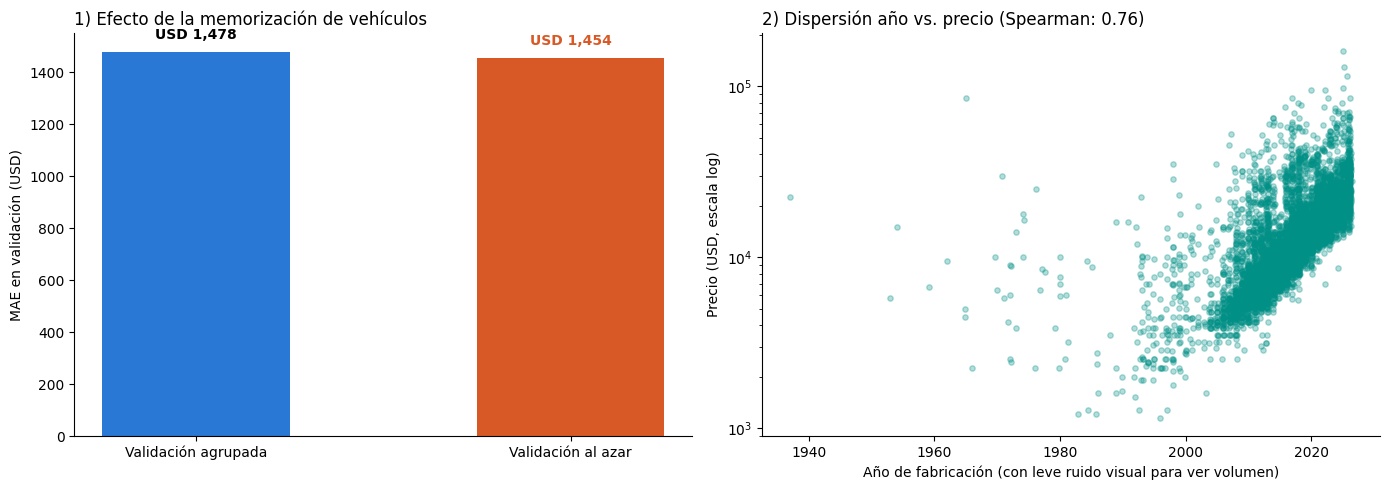

In [43]:
### reutilizar el pipeline base del HistGradientBoosting
pipe_prueba_fuga = Pipeline([
    ("ingenieria", IngenieriaAutos()),
    ("prep", preprocesador),
    ("modelo", TransformedTargetRegressor(regressor=HistGradientBoostingRegressor(random_state=SEMILLA), func=np.log1p, inverse_func=np.expm1))
])

### crear un KFold aleatorio normal
kf_azar = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

### evaluar con KFold al azar vs. GroupKFold
res_azar = cross_validate(pipe_prueba_fuga, X_train, y_train, cv=kf_azar, scoring="neg_mean_absolute_error", n_jobs=-1)
mae_azar = -res_azar["test_score"].mean()
std_azar = res_azar["test_score"].std()

### recuperar el MAE de nuestro modelo original sin ajustar
mae_agrupado = df_res[df_res["Modelo"] == "HistGradientBoosting"]["MAE"].values[0]
std_agrupado = df_res[df_res["Modelo"] == "HistGradientBoosting"]["MAE_Std"].values[0]

print(" -> test 1: fuga de datos por partición aleatoria")
print(f"  - MAE con GroupKFold: USD {mae_agrupado:,.0f} ± {std_agrupado:,.0f}")
print(f"  - MAE con KFold al azar: USD {mae_azar:,.0f} ± {std_azar:,.0f}")
print(f"  - al azar el error parece USD {mae_agrupado - mae_azar:,.0f} más bajo ({(mae_agrupado - mae_azar) / std_agrupado:.1f} desvíos): optimista, pero chico")
print(f"  - claves con más de una publicación en train: {(g_train.value_counts() > 1).sum()} de {g_train.nunique()} vehículos\n")

### test de 'FABRICADO_EN' (¿hace trampa?)
corr_spearman = X_train["fabricado_en"].corr(y_train, method="spearman")

print(" -> test 2: ¿La variable 'fabricado_en' hace trampa?")
print(f"  - correlación de Spearman (año vs. precio): {corr_spearman:.2f}")

### gráficos
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

### MAE aleatorio vs. agrupado
axs[0].bar(["Validación agrupada\n", "Validación al azar\n"],
           [mae_agrupado, mae_azar], color=["#2a78d6", "#d95926"], width=0.5)
axs[0].text(0, mae_agrupado + 50, f"USD {mae_agrupado:,.0f}", ha="center", fontweight="bold")
axs[0].text(1, mae_azar + 50, f"USD {mae_azar:,.0f}", ha="center", fontweight="bold", color="#d95926")
axs[0].set_ylabel("MAE en validación (USD)")
axs[0].set_title("1) Efecto de la memorización de vehículos", loc="left")
axs[0].spines[["top", "right"]].set_visible(False)

### dispersión fabricado_en vs. precio
jitter = np.random.default_rng(SEMILLA).normal(0, 0.15, size=len(X_train))
axs[1].scatter(X_train["fabricado_en"] + jitter, y_train, alpha=0.3, s=15, color="#009086")
axs[1].set_yscale("log")
axs[1].set_xlabel("Año de fabricación (con leve ruido visual para ver volumen)")
axs[1].set_ylabel("Precio (USD, escala log)")
axs[1].set_title(f"2) Dispersión año vs. precio (Spearman: {corr_spearman:.2f})", loc="left")
axs[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Lectura.**

- **Validación al azar:** el error parece USD 16 más bajo y el desvío más chico (42 contra 66). Va para el lado optimista, como anticipa la consigna, pero la diferencia es chica (0,2 desvíos) porque en este dataset sólo 232 de 6.800 vehículos aparecen más de una vez. Con más cosechas mensuales del pipeline habría más republicaciones y la diferencia crecería; por eso la validación por vehículo queda fija.
- **`fabricado_en`:** Spearman 0,76 con el precio. Es alta pero lejos de 1, y el gráfico muestra mucha dispersión para un mismo año: el año no "contiene" el precio. Además se conoce antes de publicar, así que no es fuga: es la depreciación.

#
### ¿El `TargetEncoder` de modelo filtra el precio?

- Es el otro lugar donde podría colarse el objetivo, porque reemplaza cada modelo por un promedio de precios. Va adentro del pipeline (se ajusta sólo con el entrenamiento de cada pedazo) y hace *cross-fitting* interno.
- Chequeo empírico: si hubiera fuga, el modelo andaría **mejor** justo en los modelos raros (donde el promedio "memorizado" es casi el precio de la fila). Se mide el error en test según cuántos avisos de ese modelo hay en el entrenamiento.

In [44]:
mod_train = IngenieriaAutos().transform(X_train)["modelo_n"].value_counts()
mod_test = IngenieriaAutos().transform(X_test)["modelo_n"]
frecuencia = mod_test.map(mod_train).fillna(0)
cortes = pd.cut(frecuencia, [-1, 0, 9, 49, 100_000], labels=["0 (nunca visto)", "1–9", "10–49", "50+"])

tabla_te = (pd.DataFrame({"abs": np.abs(err).values, "rel": rel.values, "frec": cortes.values})
            .groupby("frec", observed=True)
            .agg(Avisos=("abs", "size"), MAE=("abs", "mean"), Error_rel_mediano=("rel", "median")))
print(" -> MAE en test según cuántos avisos tiene ese modelo en el entrenamiento:")
display(tabla_te.round(3))

 -> MAE en test según cuántos avisos tiene ese modelo en el entrenamiento:


,Avisos,MAE,Error_rel_mediano
frec,,,
0 (nunca visto),30,7370.116,0.189
1–9,164,3415.272,0.119
10–49,498,1494.901,0.073
50+,1090,935.165,0.058


**Lectura.** Pasa lo contrario de lo que haría una fuga: en modelos con 50 o más avisos en el entrenamiento el MAE es de USD 927, y en modelos con menos de 10 avisos sube a 3.400; en los 30 autos de modelos que el entrenamiento nunca vio, a 7.300. El modelo aprende de autos parecidos, no copia precios. Es también un **límite para la app de la Entrega 4**: para modelos raros la tasación es poco confiable, y la app debería avisarlo.